# Amazon Trainium estimates

Quarterly and cumulative Trainium production, Q1 2024 – Q2 2026. The model itself lives in
`models/trainium.py`; this notebook runs it and renders tables, charts, and sanity checks.
To refresh the published CSVs and validate them in one step, run `python run_chip_model.py trainium`.

Methodology write-up for the 2026 H1 update: [working draft](https://docs.google.com/document/d/16j2nTJls-jIQ2gRBAo7Wq-fZUwV0UgRZP8sDuBL0XZ0/edit?tab=t.yjy8uqrdkmkf).

In [ ]:
# Colab only opens this notebook file, so fetch the rest of the repo and install squigglepy.
# Locally, it only moves to the repo root so the imports and file paths resolve.
import os, sys
if "google.colab" in sys.modules:
    !pip install -q squigglepy
    if not os.path.exists("ai-chip-counts"):
        !git clone -q --depth 1 https://github.com/epoch-research/ai-chip-counts.git
    %cd ai-chip-counts
elif os.path.basename(os.getcwd()) == "notebooks":
    # Jupyter starts in notebooks/, but every path here is relative to the repo root.
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import squigglepy as sq
from squigglepy.numbers import K, M

from models import trainium as tm

inputs = tm.load_inputs()
specs = inputs['specs']
for chip, spec in specs.items():
    print(f"  {chip}: TOPS={spec['tops']:.0f}, TDP={spec['tdp']:.0f}W, H100e={spec['tops'] / tm.H100_TOPS:.3f}")

results = tm.run_model(inputs=inputs)
quarterly = results['quarterly_samples']
cumulative = results['cumulative_samples']

COLORS = {'Trainium1': '#9aa5b1', 'Trainium2': '#3b82c4', 'Trainium3': '#e07b39'}

def h100e_ratio(chip):
    return specs[chip]['tops'] / tm.H100_TOPS

Loaded Trainium specs from epoch.ai chip_types.csv
  Trainium1: TOPS=420, TDP=300W, H100e=0.212
  Trainium2: TOPS=1299, TDP=500W, H100e=0.656
  Trainium3: TOPS=2517, TDP=700W, H100e=1.272
Simulation complete.


## Trainium2, 2024–2025

Amazon disclosed in its [Q4 2025 earnings](https://s2.q4cdn.com/299287126/files/doc_earnings/2025/q4/earnings-result/AMZN-Q4-2025-Earnings-Release.pdf) (February 5, 2026) that "Trainium2 is fully subscribed with 1.4 million chips landed." This is the anchor for cumulative production through 2025. "Landed" likely means operational; possible time lags are modeled as ~10% uncertainty in either direction.

[SemiAnalysis](https://newsletter.semianalysis.com/p/amazons-ai-resurgence-aws-anthropics-multi-gigawatt-trainium-expansion) estimated relative quarterly Trainium2 package production, which implies:

- **2024 was ~20% of the 2024–2025 total** (2025 production ~4x higher than 2024). We assume a range of 15–30%.
- **2024 quarterly growth was ~2.5x** per quarter (digitized from the SemiAnalysis chart). We model this as 2–3x.
- **2025 H1 was 40–45% of 2025 production**, implying moderate within-year growth (~11–22% per quarter).
- Within each year, production grows smoothly and exponentially from quarter to quarter.

This yields roughly 300k Trainium2 in 2024, 450k in 2025 H1, and 650k in 2025 H2.

## Trainium2, H1 2026

Two sell-side forecasts, relayed by media reports, pin down Trainium2 in 2026:

- **Morgan Stanley** (July 2025): 500k Trainium2 produced in H1 2026, against 1.1M in 2025 and 300k in 2024, for a lifetime total of 1.9M — implying Trainium2 production ends after H1 2026.
- **JPMorgan** (January 2026): 2.1M Trainium shipments in 2026, of which 600k Trainium2 and 1.5M Trainium3. It doesn't say when in 2026 the Trainium2 ship, but it is consistent with Morgan Stanley if they are front-loaded into H1. KGI (2.4–2.5M) and Yuanta (2M) give similar totals.

These are supply-chain-based (e.g. CoWoS allocations), so they likely count finished chip packages rather than assembled servers. They are still third-party estimates from late 2025 / early 2026, so the true figure is fairly uncertain.

500–600k in H1 2026 is below a naive extrapolation of 2025 (over 300k in Q4 2025, so 600k+ per half before growth), which suggests production began ramping down by mid-2026 — plausible given Trainium3 timelines.

**Modeling assumptions:** H1 2026 Trainium2 shipments are lognormal with a 90% interval of 400k to 900k (median ~600k), wide because both forecasts are third-party estimates. 50–65% of them ship in Q1. No Trainium2 is produced after H1 2026.

## Trainium3, H1 2026

Trainium3 began shipping in H1 2026 but is back-loaded into H2: Andy Jassy wrote on April 9, 2026 that Trainium3 "just started shipping at the start of 2026", and SemiAnalysis reports Trainium3 wafer-in from early 2026 "for a big second half output ramp."

Alchip, one of Amazon's Trainium3 design partners, reported Q2 2026 North American revenue up over $100M from "3nm accelerator shipments to a North American customer that began in May" — clearly Trainium3 — suggesting roughly 10k–100k chips. Alchip is not the only source: SemiAnalysis reports two Trainium3 tapeouts, "Anita" (Alchip) and "Mariana" (Amazon itself), with Mariana carrying the majority of volume, and Jassy's April statement predates Alchip's May start. So H1 volumes may have exceeded 100k.

**Modeling assumptions:** H1 2026 Trainium3 shipments are lognormal with a 90% interval of 30k (conservative extrapolation from Alchip revenue) to 300k (~20% of JPMorgan's 1.5M for 2026), median just under 100k. All of it is assigned to Q2; Q1 shipments were positive but negligible and are rounded down to zero.

## Trainium1

Very rough estimate: 200k–1M units over 2024 (90% CI), split evenly across quarters, with no production afterwards. The even split is naive: SemiAnalysis models a ramp-down through 2024, but shipments may lag production.

## Quarterly production

In [2]:
def percentile_table(samples_by_quarter, round_to=5000):
    """One row per chip-quarter with production: p5 / median / p95 units and median H100e."""
    rows = []
    for q in tm.QUARTERS:
        for chip in tm.CHIPS:
            arr = samples_by_quarter[q][chip]
            if np.median(arr) == 0:
                continue
            p5, p50, p95 = (round(np.percentile(arr, pct) / round_to) * round_to for pct in (5, 50, 95))
            rows.append({'Quarter': q, 'Chip': chip, 'p5': int(p5), 'Median': int(p50), 'p95': int(p95),
                         'H100e (median)': int(np.median(arr) * h100e_ratio(chip))})
    return pd.DataFrame(rows)

percentile_table(quarterly).style.format(thousands=',', precision=0).hide(axis='index')

Quarter,Chip,p5,Median,p95,H100e (median)
Q1 2024,Trainium1,"50,000","110,000","250,000","23,575"
Q1 2024,Trainium2,"5,000","15,000","25,000","8,465"
Q2 2024,Trainium1,"50,000","110,000","250,000","23,575"
Q2 2024,Trainium2,"20,000","30,000","50,000","20,741"
Q3 2024,Trainium1,"50,000","110,000","250,000","23,575"
Q3 2024,Trainium2,"50,000","80,000","105,000","51,069"
Q4 2024,Trainium1,"50,000","110,000","250,000","23,575"
Q4 2024,Trainium2,"125,000","190,000","265,000","124,696"
Q1 2025,Trainium2,"180,000","210,000","250,000","139,359"
Q2 2025,Trainium2,"215,000","245,000","285,000","162,127"


## Cumulative production by chip

In [3]:
percentile_table(cumulative).style.format(thousands=',', precision=0).hide(axis='index')

Quarter,Chip,p5,Median,p95,H100e (median)
Q1 2024,Trainium1,"50,000","110,000","250,000","23,575"
Q1 2024,Trainium2,"5,000","15,000","25,000","8,465"
Q2 2024,Trainium1,"100,000","220,000","500,000","47,150"
Q2 2024,Trainium2,"25,000","45,000","70,000","29,231"
Q3 2024,Trainium1,"150,000","335,000","750,000","70,726"
Q3 2024,Trainium2,"80,000","120,000","175,000","80,404"
Q4 2024,Trainium1,"195,000","445,000","1,000,000","94,301"
Q4 2024,Trainium2,"210,000","315,000","430,000","206,789"
Q1 2025,Trainium1,"195,000","445,000","1,000,000","94,301"
Q1 2025,Trainium2,"430,000","530,000","635,000","346,623"


## Charts

### New compute per quarter

Bars stack each chip's median H100e; the whisker is the 90% interval on the all-chip total.

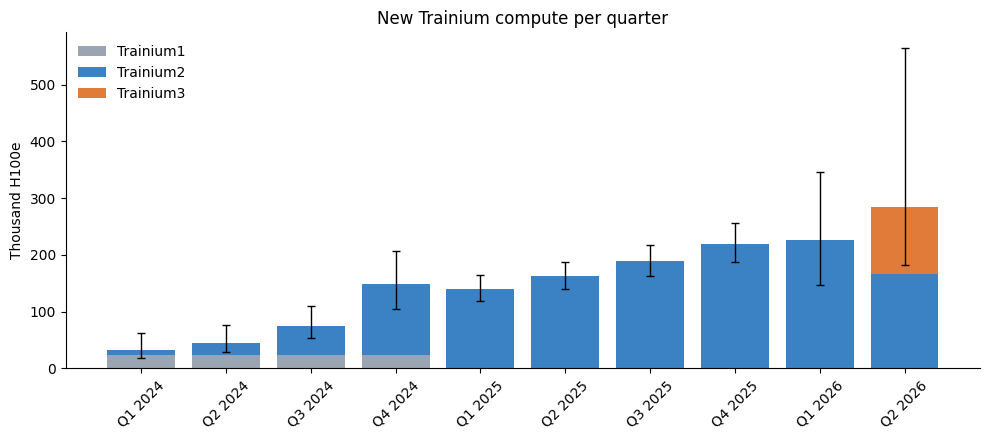

In [4]:
fig, ax = plt.subplots(figsize=(10, 4.5))
bottom = np.zeros(len(tm.QUARTERS))
for chip in tm.CHIPS:
    medians = np.array([np.median(quarterly[q][chip]) * h100e_ratio(chip) for q in tm.QUARTERS])
    ax.bar(tm.QUARTERS, medians / 1e3, bottom=bottom / 1e3, label=chip, color=COLORS[chip])
    bottom += medians

totals = np.array([sum(quarterly[q][chip] * h100e_ratio(chip) for chip in tm.CHIPS) for q in tm.QUARTERS])
p5, p95 = np.percentile(totals, 5, axis=1), np.percentile(totals, 95, axis=1)
ax.errorbar(tm.QUARTERS, bottom / 1e3, yerr=[np.clip(bottom - p5, 0, None) / 1e3, (p95 - bottom) / 1e3],
            fmt='none', ecolor='black', capsize=3, linewidth=1)

ax.set_ylabel('Thousand H100e')
ax.set_title('New Trainium compute per quarter')
ax.legend(frameon=False, loc='upper left')
ax.spines[['top', 'right']].set_visible(False)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Units per quarter, by chip

Median with shaded 90% interval. Trainium2 peaks in Q4 2025 and winds down through H1 2026 as Trainium3 begins.

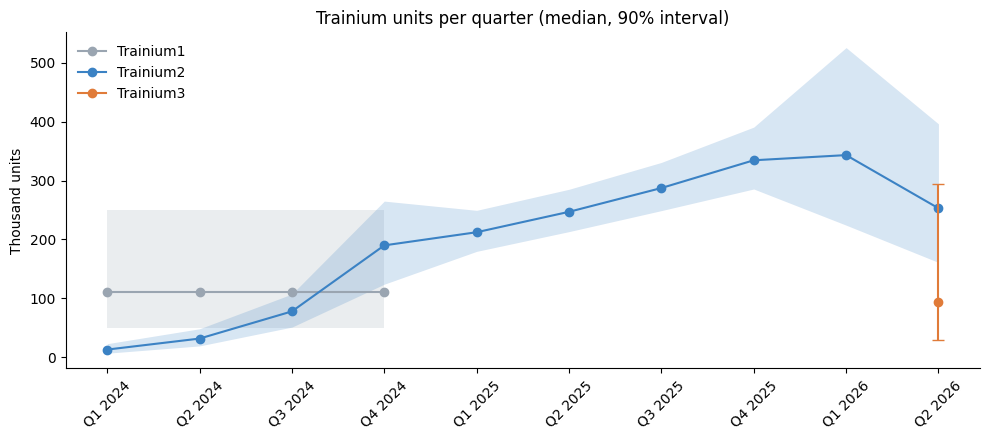

In [5]:
x = np.arange(len(tm.QUARTERS))
fig, ax = plt.subplots(figsize=(10, 4.5))
for chip in tm.CHIPS:
    arr = np.array([quarterly[q][chip] for q in tm.QUARTERS])
    produced = np.median(arr, axis=1) > 0
    p5, p50, p95 = (np.percentile(arr, pct, axis=1) / 1e3 for pct in (5, 50, 95))
    ax.plot(x[produced], p50[produced], marker='o', color=COLORS[chip], label=chip)
    ax.fill_between(x[produced], p5[produced], p95[produced], color=COLORS[chip], alpha=0.2, linewidth=0)
    # A band can't be drawn for a chip with a single quarter of production, so use a whisker
    if produced.sum() == 1:
        ax.errorbar(x[produced], p50[produced], yerr=[p50[produced] - p5[produced], p95[produced] - p50[produced]],
                    fmt='none', ecolor=COLORS[chip], capsize=4)

ax.set_xticks(x, tm.QUARTERS, rotation=45)
ax.set_ylabel('Thousand units')
ax.set_title('Trainium units per quarter (median, 90% interval)')
ax.legend(frameon=False, loc='upper left')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

### Cumulative compute

Stacked medians by chip, with the 90% interval on the cumulative total.

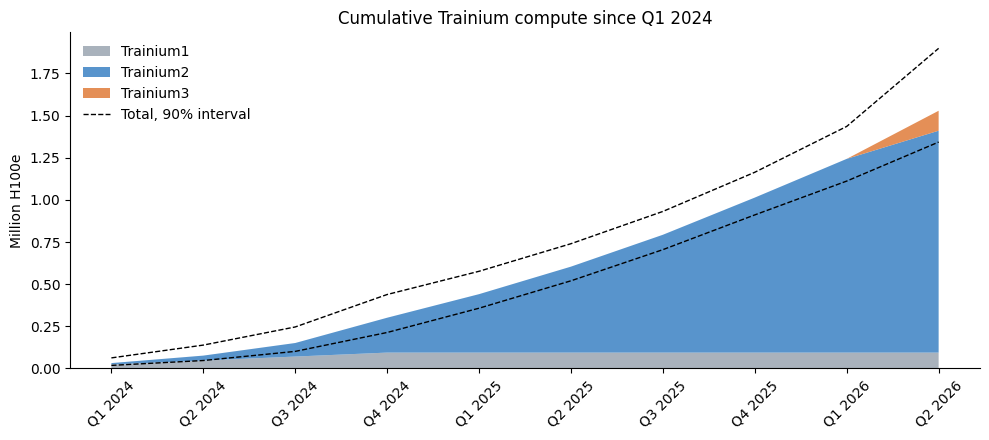

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.5))
medians_by_chip = [np.array([np.median(cumulative[q][chip]) * h100e_ratio(chip) for q in tm.QUARTERS]) / 1e6
                   for chip in tm.CHIPS]
ax.stackplot(x, *medians_by_chip, labels=tm.CHIPS, colors=[COLORS[c] for c in tm.CHIPS], alpha=0.85)

cumulative_total = np.array([sum(cumulative[q][chip] * h100e_ratio(chip) for chip in tm.CHIPS) for q in tm.QUARTERS])
ax.plot(x, np.percentile(cumulative_total, 5, axis=1) / 1e6, color='black', linestyle='--', linewidth=1,
        label='Total, 90% interval')
ax.plot(x, np.percentile(cumulative_total, 95, axis=1) / 1e6, color='black', linestyle='--', linewidth=1)

ax.set_xticks(x, tm.QUARTERS, rotation=45)
ax.set_ylabel('Million H100e')
ax.set_title('Cumulative Trainium compute since Q1 2024')
ax.legend(frameon=False, loc='upper left')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

### H1 2026 inputs against the forecasts

Distributions of the two new H1 2026 inputs, with the forecasts that informed them.

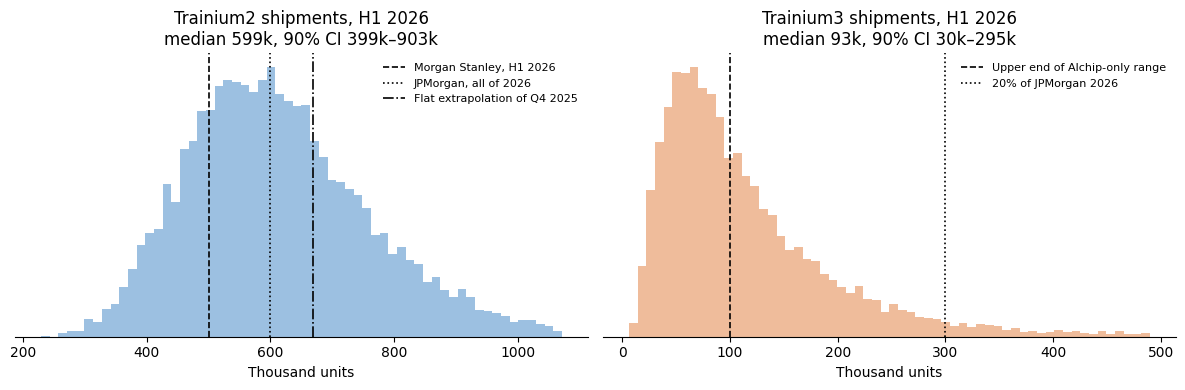

In [7]:
trainium2_h1_2026 = quarterly['Q1 2026']['Trainium2'] + quarterly['Q2 2026']['Trainium2']
trainium3_h1_2026 = quarterly['Q2 2026']['Trainium3']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
panels = [
    (axes[0], trainium2_h1_2026, 'Trainium2', 'Trainium2 shipments, H1 2026',
     [(500 * K, 'Morgan Stanley, H1 2026'), (600 * K, 'JPMorgan, all of 2026'),
      (2 * np.median(quarterly['Q4 2025']['Trainium2']), 'Flat extrapolation of Q4 2025')]),
    (axes[1], trainium3_h1_2026, 'Trainium3', 'Trainium3 shipments, H1 2026',
     [(100 * K, 'Upper end of Alchip-only range'), (300 * K, '20% of JPMorgan 2026')]),
]
line_styles = ['--', ':', '-.']
for ax, arr, chip, title, markers in panels:
    upper = np.percentile(arr, 99)
    ax.hist(arr[arr <= upper] / 1e3, bins=60, color=COLORS[chip], alpha=0.5)
    for (value, label), style in zip(markers, line_styles):
        ax.axvline(value / 1e3, color='black', linestyle=style, linewidth=1.2, label=label)
    ax.set_title(f"{title}\nmedian {np.median(arr) / 1e3:,.0f}k, 90% CI "
                 f"{np.percentile(arr, 5) / 1e3:,.0f}k–{np.percentile(arr, 95) / 1e3:,.0f}k")
    ax.legend(frameon=False, fontsize=8, loc='upper right')
    ax.set_xlabel('Thousand units')
    ax.set_yticks([])
    ax.spines[['top', 'right', 'left']].set_visible(False)
plt.tight_layout()
plt.show()

## Sanity checks

**Against the forecasts the model is built from.** Trainium2 lifetime production should land near Morgan Stanley's 1.9M, and H1 2026 should mostly sit below a flat extrapolation of Q4 2025. Trainium3 in H1 should be a small slice of JPMorgan's 1.5M for 2026, since the ramp is back-loaded.

**Against Anthropic's Trainium data center capacity** (not part of the published methodology). Anthropic uses a large majority of Trainium capacity, so capacity coming online for it is a rough floor on Trainium volumes. Our [AI Data Centers directory](https://epoch.ai/data/ai-data-centers) has roughly 400k H100e of new Trainium capacity in H1 2026 across [New Carlisle](https://epoch.ai/data/ai-data-centers/directory/anthropic-amazon-new-carlisle) (~220k H100e through June), [Ridgeland](https://epoch.ai/data/ai-data-centers/directory/amazon-ridgeland) (~171k through May), and [Berwick](https://epoch.ai/data/ai-data-centers/directory/aws-berwick) (~20k). That is likely an underestimate: the directory is not comprehensive, and Trainium sites without an identifiable tenant are hard to spot. Timing also differs, since chips come online months after they ship and capacity additions are lumpy.

In [8]:
def ci(arr):
    p5, p50, p95 = np.percentile(arr, [5, 50, 95])
    return f"{p50:>11,.0f}   (90% CI {p5:,.0f} – {p95:,.0f})"

trainium2_lifetime = cumulative['Q2 2026']['Trainium2']
trainium2_flat_extrapolation = 2 * quarterly['Q4 2025']['Trainium2']

print(f"Trainium2 lifetime (through Q2 2026): {ci(trainium2_lifetime)}   Morgan Stanley: 1.9M")
print(f"Trainium2 H1 2026:                    {ci(trainium2_h1_2026)}   MS: 500k, JPM: 600k (full 2026)")
print(f"  Q4 2025 x 2 (flat extrapolation):   {ci(trainium2_flat_extrapolation)}")
print(f"  share of samples where H1 2026 < flat extrapolation: {np.mean(trainium2_h1_2026 < trainium2_flat_extrapolation):.0%}")
print()
print(f"Trainium3 H1 2026:                    {ci(trainium3_h1_2026)}")
print(f"  as share of JPMorgan's 1.5M for 2026: {np.median(trainium3_h1_2026) / (1.5 * M):.0%} (median)")
print()

h1_2026_new_h100e = sum((quarterly['Q1 2026'][chip] + quarterly['Q2 2026'][chip]) * h100e_ratio(chip)
                        for chip in tm.CHIPS)
print(f"New Trainium H100e in H1 2026:        {ci(h1_2026_new_h100e)}   data center directory: ~400k (likely a floor)")

Trainium2 lifetime (through Q2 2026):   2,005,116   (90% CI 1,754,916 – 2,330,559)   Morgan Stanley: 1.9M
Trainium2 H1 2026:                        599,209   (90% CI 398,852 – 902,931)   MS: 500k, JPM: 600k (full 2026)
  Q4 2025 x 2 (flat extrapolation):       669,158   (90% CI 571,569 – 781,842)
  share of samples where H1 2026 < flat extrapolation: 66%

Trainium3 H1 2026:                         93,045   (90% CI 29,714 – 294,872)
  as share of JPMorgan's 1.5M for 2026: 6% (median)

New Trainium H100e in H1 2026:            532,729   (90% CI 356,741 – 845,447)   data center directory: ~400k (likely a floor)


## Sensitivity: H1 2026 inputs

Cumulative compute through Q2 2026 if each H1 2026 input is pinned near a single forecast or the end of its range (same seed, so runs differ only in the parameter).

In [9]:
scenarios = {
    'Baseline': {},
    'Trainium2 H1 ~500k (Morgan Stanley)': {'trainium2_2026_h1_units': sq.norm(475 * K, 525 * K)},
    'Trainium2 H1 ~600k (JPMorgan)': {'trainium2_2026_h1_units': sq.norm(575 * K, 625 * K)},
    'Trainium3 H1 ~30k': {'trainium3_2026_h1_units': sq.norm(27 * K, 33 * K)},
    'Trainium3 H1 ~300k': {'trainium3_2026_h1_units': sq.norm(270 * K, 330 * K)},
}

rows = []
for name, overrides in scenarios.items():
    run = tm.run_model(params=overrides, inputs=inputs)
    total_h100e = sum(run['cumulative_samples']['Q2 2026'][chip] * h100e_ratio(chip) for chip in tm.CHIPS)
    p5, p50, p95 = np.percentile(total_h100e, [5, 50, 95])
    rows.append({'Scenario': name, 'H100e p5': int(p5), 'H100e median': int(p50), 'H100e p95': int(p95)})
pd.DataFrame(rows).style.format(thousands=',').hide(axis='index')

Simulation complete.
Simulation complete.
Simulation complete.
Simulation complete.
Simulation complete.


Scenario,H100e p5,H100e median,H100e p95
Baseline,"1,343,063","1,562,425","1,898,986"
Trainium2 H1 ~500k (Morgan Stanley),"1,327,163","1,483,076","1,765,480"
Trainium2 H1 ~600k (JPMorgan),"1,392,802","1,548,716","1,831,119"
Trainium3 H1 ~30k,"1,279,438","1,458,544","1,700,141"
Trainium3 H1 ~300k,"1,618,944","1,802,008","2,043,876"


## Export CSVs

Writes `csv_export/trainium_*.csv` and `owners_csv_export/trainium_owners_*.csv`. `python run_chip_model.py trainium` does the same and also validates against the published dataset.

In [10]:
tm.export_csvs(results)

Exported 15 rows to csv_export/trainium_chip_timelines.csv
Exported 21 rows to csv_export/trainium_cumulative_by_chip.csv
Exported 10 rows to csv_export/trainium_cumulative_totals.csv
Exported 21 rows to owners_csv_export/trainium_owners_cumulative_by_chip.csv
Exported 15 rows to owners_csv_export/trainium_owners_quarters_by_chip.csv
Exported 10 rows to owners_csv_export/trainium_owners_cumulative_totals.csv


['csv_export/trainium_chip_timelines.csv',
 'csv_export/trainium_cumulative_by_chip.csv',
 'csv_export/trainium_cumulative_totals.csv',
 'owners_csv_export/trainium_owners_cumulative_by_chip.csv',
 'owners_csv_export/trainium_owners_quarters_by_chip.csv',
 'owners_csv_export/trainium_owners_cumulative_totals.csv']

## Canonical export

Alongside the legacy CSVs above, `tm.export_canonical` writes the canonical sales and owners tables (see `docs/schema.md`) to `outputs/canonical/trainium/`. It hands the schema library the same per-quarter unit samples, and the library computes H100e and power from the shared chip-spec table, taking percentiles only after summing across chips. Amazon owns every Trainium it makes, so the owners tables are the sales numbers with Amazon as the owner. `python run_chip_model.py trainium` writes these too.

In [ ]:
tm.export_canonical(results)